# Cell-to-tissue coupling: a reduced cardiac wave

How do local excitation and spatial current exchange produce a traveling wave, and how should its speed be measured and checked?

Fall 2024.


# A reduced cardiac wave
This is a new homogeneous strand, not the neuronal HH cable. Predict what removing D will do to a remote sensor. Explain why the full voltage integral can change even though a sealed diffusion step conserves its sum.

In [1]:
import numpy as np
from demo import simulate, run, crossing, diffuse
from IPython.display import SVG, display
probe = np.array([0.2,0.8,0.4])
after = diffuse(probe, dx=0.1, D=0.001, dt=0.2)
print("Diffusion-only integral change:",0.1*np.sum(after-probe))

Diffusion-only integral change: 0.0


## Implement a measurement
Complete the fraction expression for one known upward-crossing bracket. Keep the bracket guard. This guided example is separate from the assigned speed problem. Predict the crossing before running the check.

In [2]:
def my_crossing(t0,t1,y0,y1,threshold=0.5):
    if not (t1>t0 and y0<threshold<=y1):
        return None
    fraction = None  # TODO: linear fraction of this interval
    if fraction is None:
        return None
    return t0 + fraction*(t1-t0)

trial = my_crossing(2.,4.,0.2,0.8)
if trial is None:
    print("Complete the fraction expression, then rerun.")
else:
    np.testing.assert_allclose(trial,3.,rtol=0,atol=1e-12)
    print("Guided crossing check passed:",trial,"ms")

Complete the fraction expression, then rerun.


In [3]:
baseline = simulate()
print("Sensors (cm):",baseline["sensor_positions_cm"])
print("Arrival times (ms):",baseline["arrival_ms"])
print("Speed (m/s):",baseline["speed_m_s"])
uncoupled = simulate(n=100,D=0,end=20)
print("With D=0, remote arrivals:",uncoupled["arrival_ms"])

Sensors (cm): [0.6 1.2]
Arrival times (ms): [20.778092371077946, 38.60532285987719]
Speed (m/s): 0.33656377549893507
With D=0, remote arrivals: [None, None]


## Run the references and refinements
Identify which reported orders concern a smooth passive field or a uniform reaction, and which quantities concern the active wave. Do not transfer an order automatically from one observable to another.

baseline [20.778092371077946, 38.60532285987719] 0.33656377549893507


space [0.3370606589275018, 0.33880660278101005, 0.3392438893040014] time [0.3246749887121444, 0.3326670170666202, 0.33699006773263906, 0.3392438893040014]


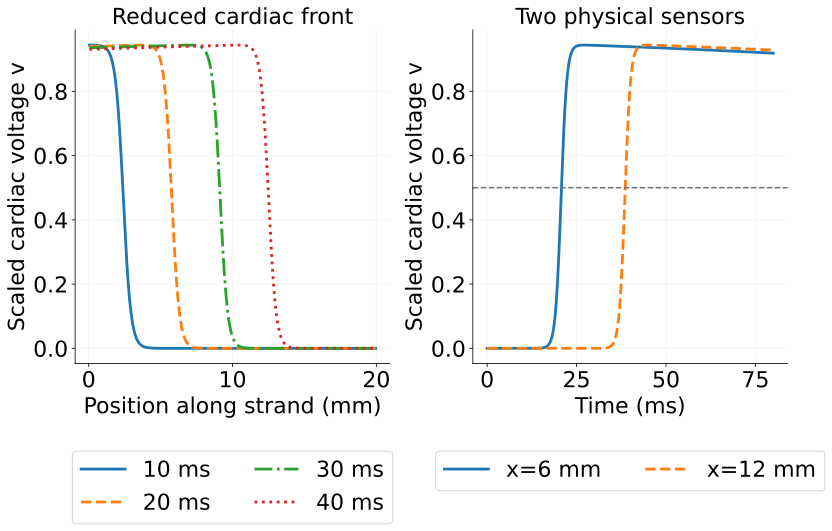

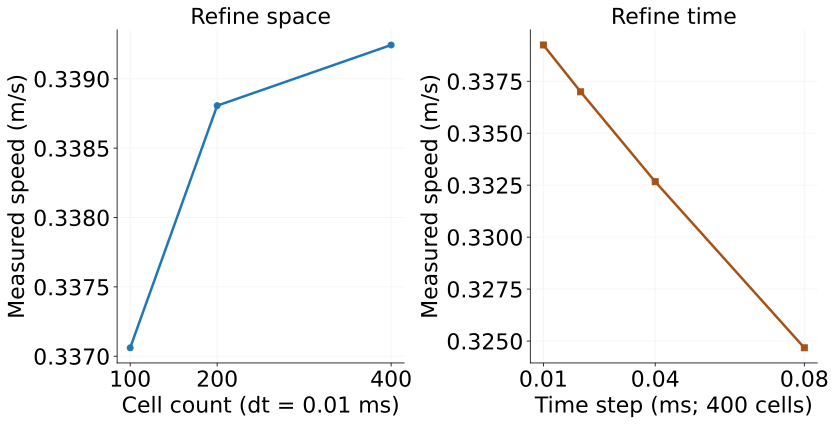

Passive spatial orders: [1.9947107288888433, 1.998678546064667, 1.9996696903886224]
Uniform reaction time orders: [0.9679645078049351, 0.9837436286305404, 0.9918118811989641]


In [4]:
results = run()
display(SVG(filename="cardiac-wave.svg"))
display(SVG(filename="wave-refinement.svg"))
print("Passive spatial orders:",results["passive_spatial_orders"])
print("Uniform reaction time orders:",results["uniform_cell_orders"])

## Modify the measurement
Keep the simulated field unchanged and compare upward crossings at thresholds 0.4 and 0.6. Predict whether the two-sensor delay must be identical. A missing or reversed arrival should remain undefined.

In [5]:
for threshold in [0.4,0.6]:
    arrivals=[crossing(baseline["time"],baseline["sensor_traces"][:,j],threshold) for j in range(2)]
    speed=None if any(t is None for t in arrivals) or arrivals[1]<=arrivals[0] else 10*np.diff(baseline["sensor_positions_cm"])[0]/(arrivals[1]-arrivals[0])
    print("Threshold",threshold,"arrivals",arrivals,"speed",speed)

Threshold 0.4 arrivals [20.44032681541463, 38.26754373816512] speed 0.33656403161522114
Threshold 0.6 arrivals [21.12448032594639, 38.951719679649244] speed 0.33656360813676706


## Record your interpretation
Report reaction-model identity, units, boundary conditions, source geometry, sensor definition, one structural check, and separate space/time observations. State one measurement needed before interpreting the speed as biological validation. Optional: test another D with its own refinement study.